# 04 — Anomaly Detection (Family B)
Models that learn what "normal" (employed) graduates look like and
flag deviations from that pattern, rather than directly learning an
employed/unemployed boundary. Each is fit **only on majority-class
training rows** (the standard anomaly-detection convention) via
`AnomalyDetectorWrapper`, which adapts them to expose `predict_proba`
so the same PR-AUC evaluation machinery used for Family A applies
here unmodified.

All three (Isolation Forest, One-Class SVM, Local Outlier Factor)
are scikit-learn built-ins and have been verified end-to-end
against the real dataset.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent.resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
from IPython.display import display

from sklearn.model_selection import train_test_split

from src.feature_engineering import CANDIDATE_FEATURES, NUMERIC_FEATURES, NOMINAL_FEATURES, TARGET_COLUMN
from src.anomaly_models import build_anomaly_models
from src.evaluation import (
    compare_models, get_out_of_fold_probabilities, find_best_threshold,
    evaluate_on_holdout, plot_precision_recall_curves, plot_confusion_matrix
)
from src.reporting import TABLES_DIR, save_table

RANDOM_STATE = 42
TEST_SIZE = 0.2

In [2]:
df_final = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "tracer_study_processed.csv")

X = df_final[CANDIDATE_FEATURES]
y = df_final[TARGET_COLUMN].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")

Train: (125, 11), Test: (32, 11)


## Build Family B models

In [3]:
models = build_anomaly_models(NUMERIC_FEATURES, NOMINAL_FEATURES)
print("Models built:", list(models.keys()))

Models built: ['B1_IsolationForest', 'B2_OneClassSVM', 'B3_LocalOutlierFactor']


## Repeated Stratified 5-Fold Cross-Validation (PR-AUC primary)

In [4]:
summary_table, raw_scores = compare_models(models, X_train, y_train)
display(summary_table.round(3))

,accuracy,precision,recall,f1,pr_auc,accuracy_std,precision_std,recall_std,f1_std,pr_auc_std,pr_auc_ci_low,pr_auc_ci_high,pr_auc_corrected_ci_low,pr_auc_corrected_ci_high
B3_LocalOutlierFactor,0.765,0.253,0.088,0.125,0.302,0.047,0.338,0.099,0.143,0.117,0.271,0.335,0.179,0.426
B1_IsolationForest,0.557,0.253,0.620,0.357,0.287,0.106,0.092,0.241,0.129,0.103,0.259,0.316,0.178,0.395
B2_OneClassSVM,0.546,0.140,0.236,0.172,0.264,0.096,0.090,0.153,0.107,0.100,0.237,0.292,0.158,0.370


## Threshold tuning and holdout evaluation (best model)

In [5]:
best_name = summary_table.index[0]
best_model = models[best_name]
print(f"Best model (by CV PR-AUC): {best_name}")

oof_proba = get_out_of_fold_probabilities(best_model, X_train, y_train)
threshold, cv_prec, cv_rec, cv_f1 = find_best_threshold(y_train, oof_proba, metric="f1")
print(f"Tuned threshold: {threshold:.3f}  (OOF precision={cv_prec:.3f}, recall={cv_rec:.3f}, f1={cv_f1:.3f})")

best_model.fit(X_train, y_train)
holdout_default = evaluate_on_holdout(best_model, X_test, y_test, threshold=0.5)
holdout_tuned = evaluate_on_holdout(best_model, X_test, y_test, threshold=threshold)

holdout_table = pd.DataFrame({"default (0.5)": holdout_default, "tuned": holdout_tuned})
display(holdout_table.round(3))
save_table(holdout_table, "family_b_holdout");

Best model (by CV PR-AUC): B3_LocalOutlierFactor
Tuned threshold: 0.049  (OOF precision=0.207, recall=0.920, f1=0.338)


,default (0.5),tuned
accuracy,0.781,0.188
precision,0.000,0.188
recall,0.000,1.000
f1,0.000,0.316
pr_auc,0.289,0.289
threshold_used,0.500,0.049


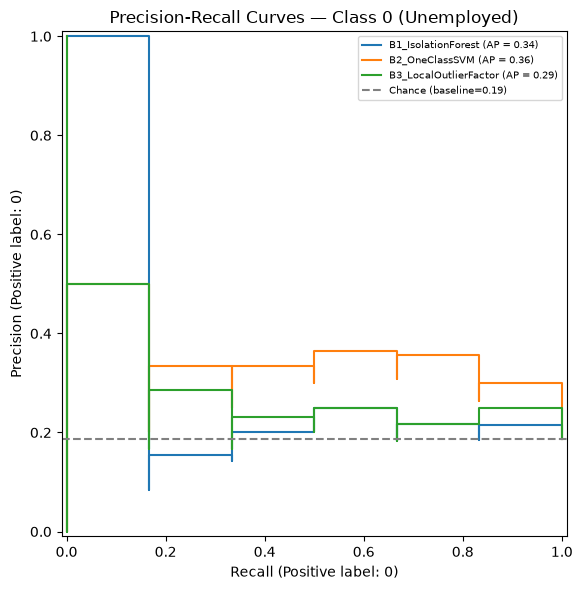

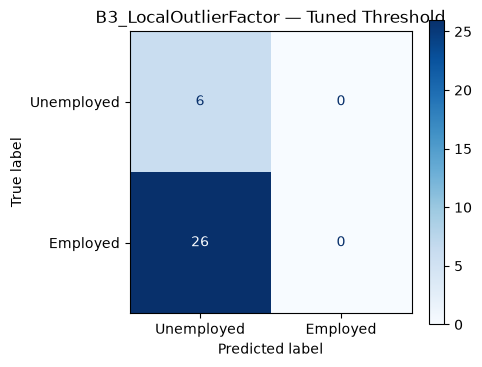

In [6]:
for m in models.values():
    m.fit(X_train, y_train)

plot_precision_recall_curves(models, X_test, y_test, save_as="family_b_pr_curves")
plot_confusion_matrix(best_model, X_test, y_test, threshold=threshold,
                       title=f"{best_name} — Tuned Threshold",
                       save_as="family_b_confusion_matrix")

## Save results for `05_evaluation.ipynb`

In [7]:
save_table(summary_table, "family_b_cv_summary")

import pickle
with open(TABLES_DIR / "family_b_raw_scores.pkl", "wb") as f:
    pickle.dump(raw_scores, f)

print("Saved Family B results to reports/tables/")

Saved Family B results to reports/tables/
